In [1]:
import matplotlib.pyplot as plt
import numpy as np

[2e-07, 6e-08, 1.8e-08, 5.3999999999999996e-09]
[0.30571236450622924, 0.6114247290124585, 0.9171370935186878, 1.222849458024917]


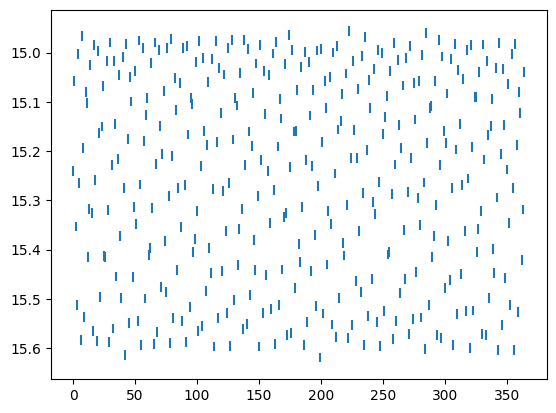

In [14]:
main_period = 3.271048593717
main_frequency = 1 / main_period
main_amplitude = 0.2e-06 # --> corresponds to ~0.3 mag amplitude
# signal_mean = 15.3
mean_flux = 0.8e-6 # relative to magnitude 0 star --> appropriate for mag ~ 15.3
n_tones = 4
decay_rate = 0.3
noise_scale = 0.01
np.random.default_rng(42)

amplitudes = []
frequencies = []
for i in range(n_tones):
    frequencies.append((i + 1) * main_frequency)
    if i:
        amplitudes.append(decay_rate * amplitudes[-1])
    else:
        amplitudes.append(main_amplitude)

print(amplitudes)
print(frequencies)

class sinusoid:

    def __init__(self, amplitude = 1, frequency = 1, phase = 0):
        self.amplitude = amplitude
        self.frequency = frequency
        self.phase = phase

    def __call__(self, x):
        return self.amplitude * np.sin(2 * np.pi * self.frequency * x)

sinusoids = [sinusoid(amplitude = a, frequency = f) for a, f in zip(amplitudes, frequencies)]
days = list(range(365))
# days = np.linspace(0, 365, 100000)
fluxes = [mean_flux + sum([s(t) for s in sinusoids]) for t in days]
mags = [-2.5 * np.log10(f) + np.random.normal(scale = noise_scale) for f in fluxes]
# mags = [-2.5 * np.log10(f) for f in fluxes]
plt.errorbar(days, mags, yerr = noise_scale, linestyle = "None")
# plt.plot(days, mags)
# plt.xlim([0, 10])




plt.gca().invert_yaxis()
plt.show()

In [15]:
np.savetxt("SnoopysLightCurve.dat", list(zip(days, mags)), fmt = "%d %.5e", header = "# day magnitudes")

Period: 3.288 days
Period: 3.259 days


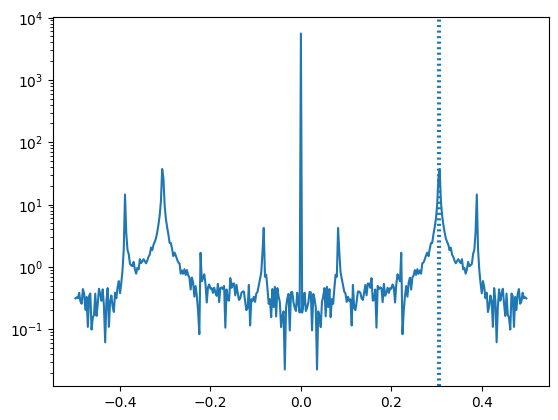

In [16]:
from scipy.fft import fft, fftfreq, fftshift, ifftshift, ifft
freqs = fftshift(fftfreq(len(days), d = days[1] - days[0]))
signal_ft = fftshift(fft(ifftshift(mags)))
plt.plot(freqs, [abs(_) for _ in signal_ft])
plt.axvline(freqs[293], linestyle = ":")
print("Period: %.3f days" % (1 / freqs[293]))
plt.axvline(freqs[294], linestyle = ":")
print("Period: %.3f days" % (1 / freqs[294]))
# plt.xlim([-1, 1])
plt.yscale("log")
plt.show()

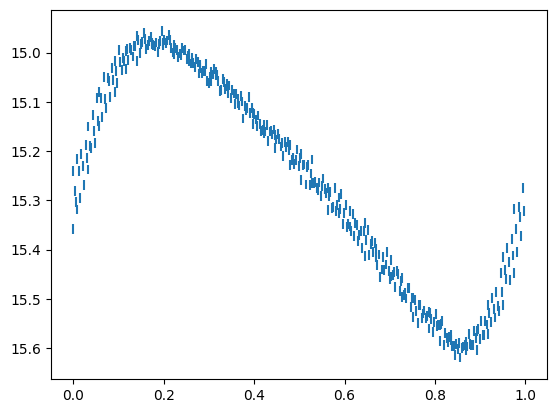

In [17]:
period = 3.27 # days
phases = []
for i in range(len(days)):
    phases.append((days[i] / period) % 1)
plt.errorbar(phases, mags, yerr = noise_scale, linestyle = "None")
plt.gca().invert_yaxis()

In [6]:
from scipy.fft import fft, ifft, fftfreq, fftshift, ifftshift

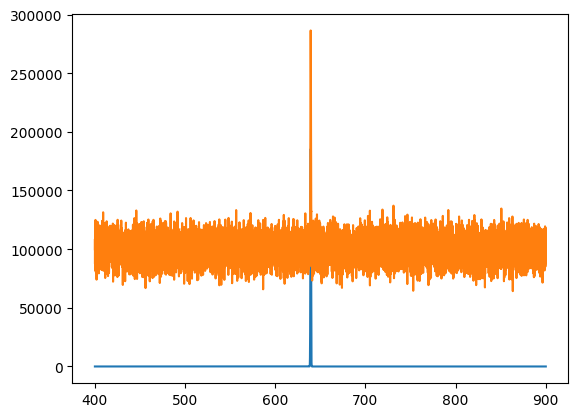

In [11]:
np.random.default_rng(42)
wavelengths = np.linspace(400, 900, 10000)
centroid = 639.3
linewidth = 0.23
background = 1.0e5
noise_level = 1.0e4
gaussian_signal = [185903 * np.exp(-(l - centroid)**2 / (2 * linewidth)**2) for l in wavelengths]
measured_signal = [background + np.random.normal(scale = noise_level) + g for g in gaussian_signal]
plt.plot(wavelengths, gaussian_signal)
plt.plot(wavelengths, measured_signal)

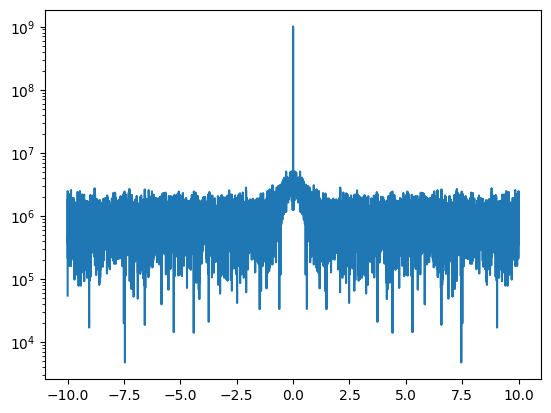

In [19]:
freqs = fftshift(fftfreq(len(wavelengths), d = wavelengths[1] - wavelengths[0]))
gaussian_ft = fftshift(fft(ifftshift(gaussian_signal)))
signal_ft = fftshift(fft(ifftshift(measured_signal)))
# plt.plot(freqs, [abs(_) for _ in gaussian_ft])
plt.plot(freqs, [abs(_) for _ in signal_ft])
plt.yscale("log")
plt.show()

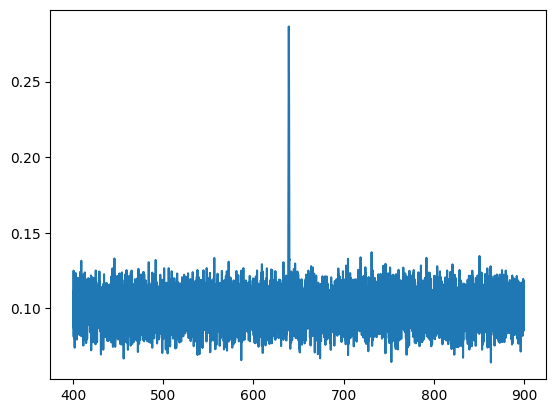

In [23]:
modified_ft = [_ / 1.0e6 for _ in signal_ft]
reconstructed = ifftshift(ifft(fftshift(modified_ft)))
plt.plot(wavelengths, reconstructed)

In [7]:
from scipy.fft import fft, ifft, fftfreq, fftshift, ifftshift
import matplotlib.pyplot as plt
import numpy as np

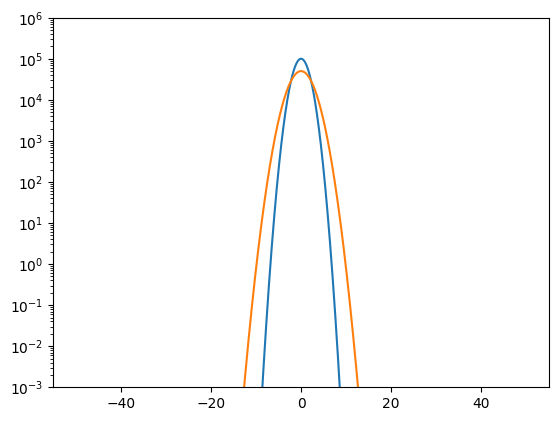

In [40]:
sampling_rate = 0.01
freq = fftshift(fftfreq(10000, d = sampling_rate))
fourier_signal_spec = [1.0e5 * np.exp(-k**2 / (2 * 1)**2) for k in freq]
fourier_noise_spec = [0.5e5 * np.exp(-k**2 / (2 * 1.5)**2) for k in freq]

plt.plot(freq, fourier_signal_spec)
plt.plot(freq, fourier_noise_spec)
plt.yscale("log")
# plt.xlim([-5, 5])
plt.ylim([1e-3, 1e6])
plt.show()

(-0.5, 0.5)

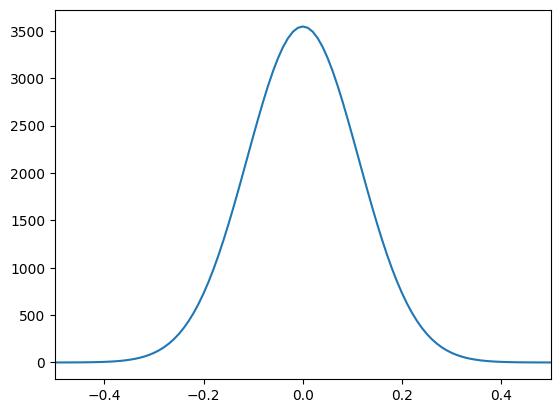

In [43]:
intrinsic = ifftshift(ifft(fftshift(fourier_signal_spec)))
convolved = [a * b for a, b in zip(fourier_signal_spec, fourier_noise_spec)]
measured = ifftshift(ifft(fftshift(convolved)))
xvals = [sampling_rate * i for i in range(len(freq))]
xvals = [x - xvals[len(xvals) // 2] for x in xvals]
# plt.plot(xvals, measured)
plt.plot(xvals, intrinsic)

# plt.yscale("log")
plt.xlim([-0.5, 0.5])

In [1]:
from scipy.fft import fft, ifft, fftfreq, fftshift, ifftshift
import matplotlib.pyplot as plt
import numpy as np

In [2]:
def not_so_simple_sinusoid(t):
    r"""
    A three-component sinusoid that this notebook uses as a baseline example 
    periodic function.

    Parameters
    ----------
    t : `float`
        Time :math:`t`, in arbitrary units (discussion assumes days).

    Returns
    -------
    The value of an arbitrary "signal" observed at the specified time.
    """
    return np.sin(2 * np.pi * t) + 0.5 * np.sin(7.2 * np.pi * t) + 0.2 * np.sin(29.8 * np.pi * t)

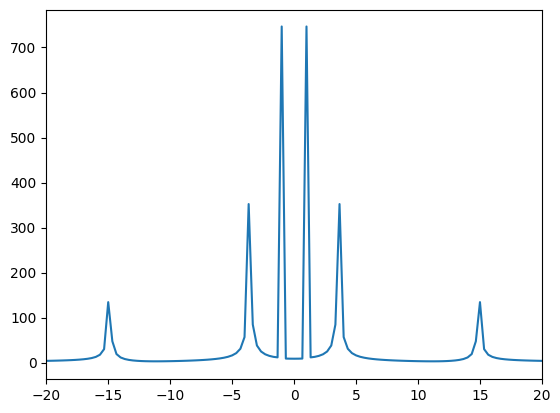

In [5]:
times = np.linspace(0, 3, 1500)
signal = [not_so_simple_sinusoid(t) for t in times]
freqs = fftshift(fftfreq(len(times), d = times[1] - times[0]))
signal_ft = fftshift(fft(ifftshift(signal)))
plt.plot(freqs, [abs(_) for _ in signal_ft])
plt.xlim([-20, 20])
plt.show()

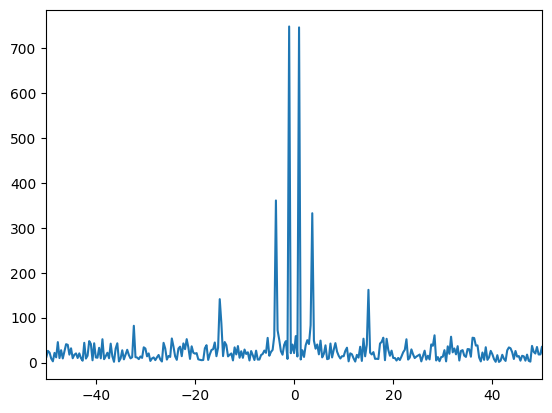

In [29]:
np.random.default_rng(42)
noise_rms = 25
noisy_ft = []
for k in range(len(freqs)):
    noisy_ft.append(signal_ft[k] + np.random.normal(scale = noise_rms))
plt.plot(freqs, [abs(_) for _ in noisy_ft])
plt.xlim([-50, 50])
plt.show()

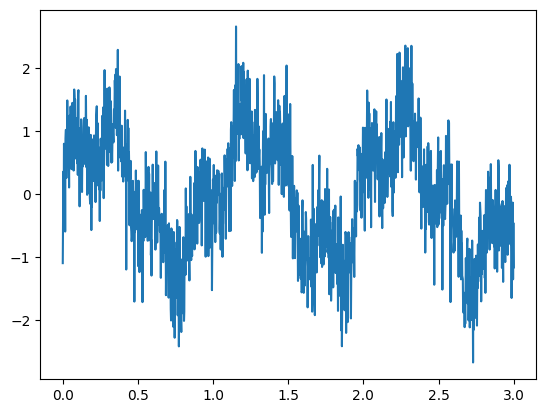

In [22]:
noisy_signal = ifftshift(ifft(fftshift(noisy_ft)))
plt.plot(times, [_.real for _ in noisy_signal])
np.savetxt("NoisySinusoid.dat", list(zip(times, [_.real for _ in noisy_signal])), fmt = "%.5e %.5e", header = "# time [days]   signal")

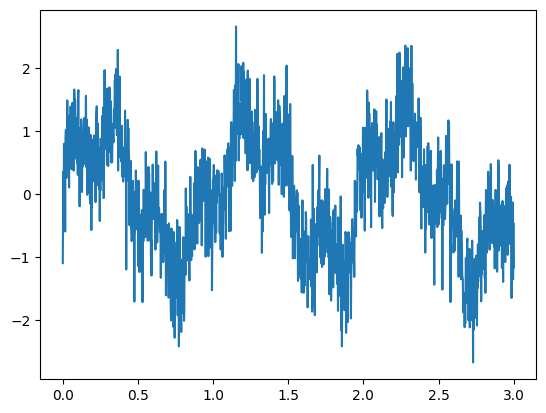

In [24]:
data = np.genfromtxt("NoisySinusoid.dat")
times = data[:,0]
signal = data[:,1]

plt.plot(times, signal)
plt.show()

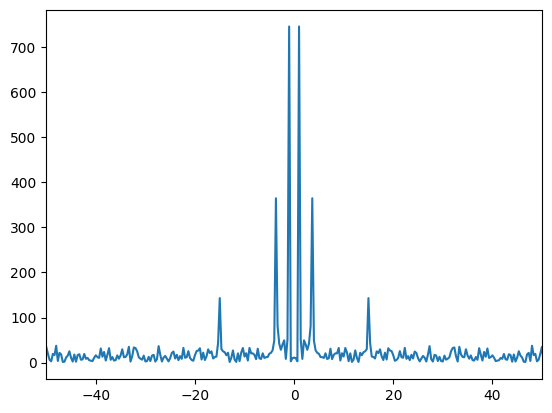

In [28]:
freqs = fftshift(fftfreq(len(times), d = times[1] - times[0]))
fk = fftshift(fft(ifftshift(signal)))
plt.plot(freqs, [abs(_) for _ in fk])
plt.xlim([-50, 50])
plt.show()

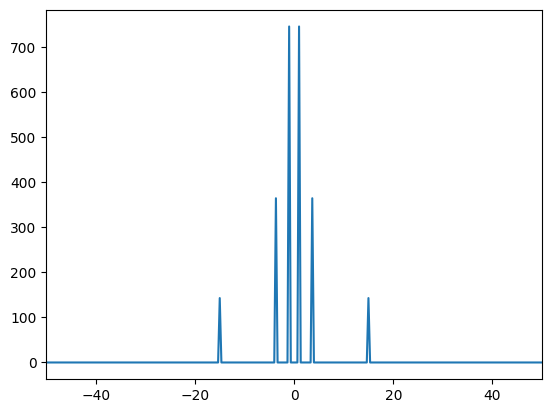

In [32]:
cleaned = []
for i in range(len(fk)):
    if abs(fk[i]) > 100:
        cleaned.append(fk[i])
    else:
        cleaned.append(0)
plt.plot(freqs, [abs(_) for _ in cleaned])
plt.xlim([-50, 50])
plt.show()

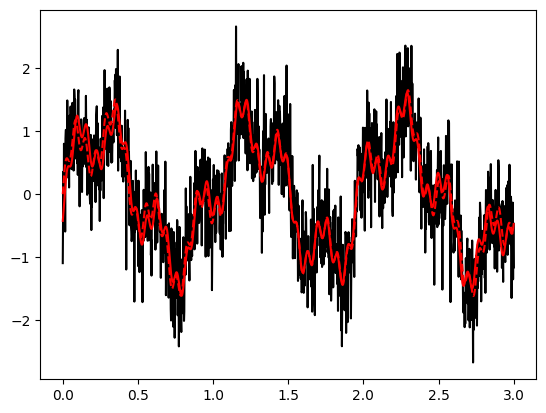

In [35]:
cleaned_signal = ifftshift(ifft(fftshift(cleaned)))
plt.plot(times, signal, c = 'k')
plt.plot(times, [_.real for _ in cleaned_signal], c = 'r')
plt.plot(times, [not_so_simple_sinusoid(t) for t in times], c = 'r', linestyle = "--")
plt.show()

In [1]:
from scipy.fft import fft, ifft, fftfreq, fftshift, ifftshift
import matplotlib.pyplot as plt
import numpy as np

In [4]:
def not_so_simple_sinusoid(t):
    r"""
    A three-component sinusoid that this notebook uses as a baseline example 
    periodic function.

    Parameters
    ----------
    t : `float`
        Time :math:`t`, in arbitrary units (discussion assumes days).

    Returns
    -------
    The value of an arbitrary "signal" observed at the specified time.
    """
    return np.sin(2 * np.pi * t) + 0.5 * np.sin(7.2 * np.pi * t) + 0.2 * np.sin(29.8 * np.pi * t)

def slow_drift(t):
    r"""
    A low-frequency "signal drift" on top of our "not-so-simple-sinusoid" from lecture.
    """
    return 1.2 * np.sin(0.1 * np.pi * t)

In [3]:
def second_sinusoid(t):
    return 3 * np.sin(1 * np.pi * t)

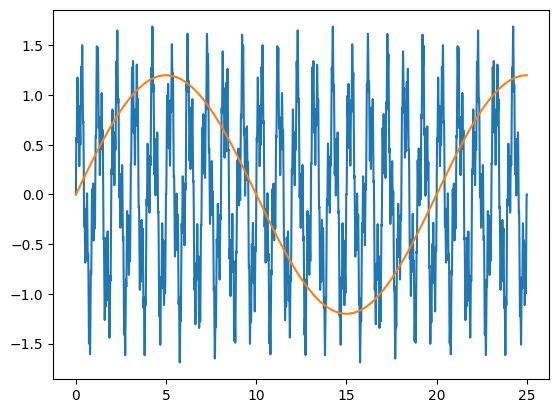

In [5]:
times = np.linspace(0, 25, 25 * 500)
signal1 = [not_so_simple_sinusoid(t) for t in times]
signal2 = [slow_drift(t) for t in times]
plt.plot(times, signal1)
plt.plot(times, signal2)

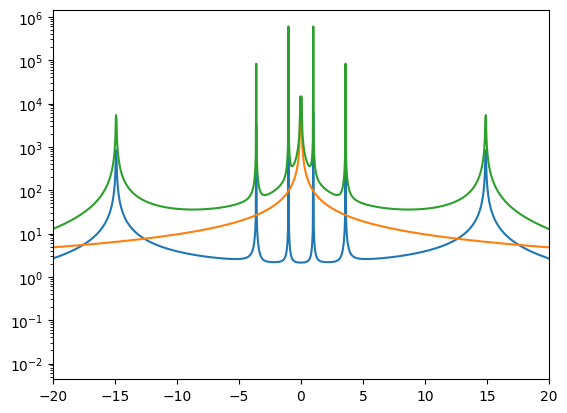

In [34]:
freqs = fftshift(fftfreq(len(times), d = times[1] - times[0]))
ft1 = fftshift(fft(ifftshift(signal1)))
ft2 = fftshift(fft(ifftshift(signal2)))
prod = [a * b for a, b in zip(ft1, ft2)]
plt.plot(freqs, [abs(_) for _ in ft1])
plt.plot(freqs, [abs(_) for _ in ft2])
plt.plot(freqs, [abs(_) for _ in prod])
plt.yscale("log")
plt.xlim([-20, 20])
plt.show()

(0.0, 5.0)

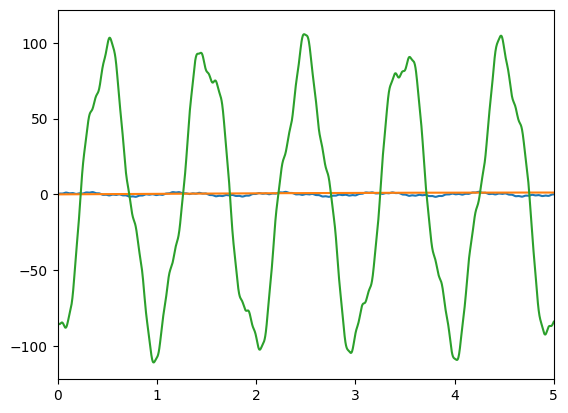

In [35]:
conv = ifftshift(ifft(fftshift(prod)))
# conv = [100 * c / len(conv) for c in conv] # common to apply a scaling factor -- discrete sums lead to big values
plt.plot(times, signal1)
plt.plot(times, signal2)
plt.plot(times, conv)
plt.xlim([0, 5])

In [ ]:
conv_ft = fftshift(fft(ifftshift(conv)))
plt.plot(freqs, conv_ft

Low-energy photons are hitting a detector in a laboratory with a time signature that you need to measure. The detector has a simple response function, measured to be

$$
r(\tau) = e^{-\tau / \tau_c},
$$

where the manufacturer reports $\tau_c = 3.2$ milliseconds. The detector reads out a number every millisecond, representing a measurement of the number of incident photons since the last readout. Due to the imperfect instrument response, a perfectly instantaneous pulse of photons gets smeared out over a function of time given by $r(t)$. Given the signal in the file, deconvolve the instrument response and reconstruct the signal. Plot its power spectral density.

[np.float64(0.9980019986673331), np.float64(0.9782314265244696), np.float64(0.9588525124377806), np.float64(0.9398574976013063), np.float64(0.9212387769122192), np.float64(0.9029888959259413), np.float64(0.8851005478715811), np.float64(0.8675665707264952), np.float64(0.8503799443488038), np.float64(0.8335337876667104)]
[np.float64(0.019810152854667376), np.float64(0.019417710698542087), np.float64(0.01903304288151626), np.float64(0.018655995392743985), np.float64(0.018286417272357754), np.float64(0.017924160551028117), np.float64(0.017569080190720652), np.float64(0.01722103402662657), np.float64(0.016879882710243668), np.float64(0.01654548965358488)]


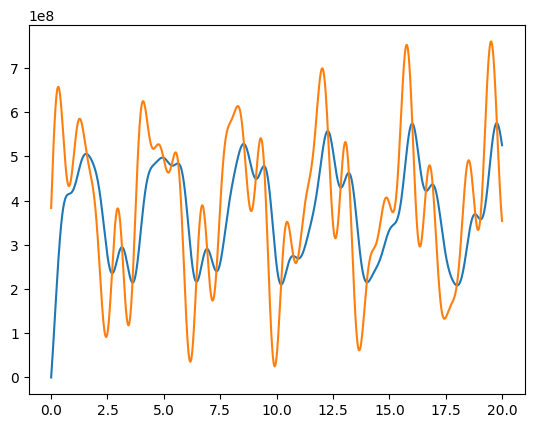

In [166]:
mean_number = 382017509 # per millisecond
sinusoids = [
    sinusoid(amplitude = 0.5, frequency = 0.27),
    sinusoid(amplitude = 0.2, frequency = 1.09),
    sinusoid(amplitude = 0.3, frequency = 0.78)
]
times = np.linspace(0.001, 20, 2000)
# print(times)
intrinsic = np.array([mean_number * (1 + sum([s(t) for s in sinusoids])) for t in times])
# print(intrinsic)

def instrument_response(t):
    return np.exp(-t / 0.5)
    # return t == 0
    # return int(t <= 0.01)

resp = [instrument_response(t) for t in times]
print(resp[:10])
norm = sum(resp)
resp = [_ / norm for _ in resp]
print(resp[:10])
measured = []
for i in range(len(times)):
    measured.append(0)
    for j in range(i):
        measured[-1] += intrinsic[j] * resp[i - j]

plt.plot(times, measured)
# print(measured)
plt.plot(times, intrinsic)
plt.show()

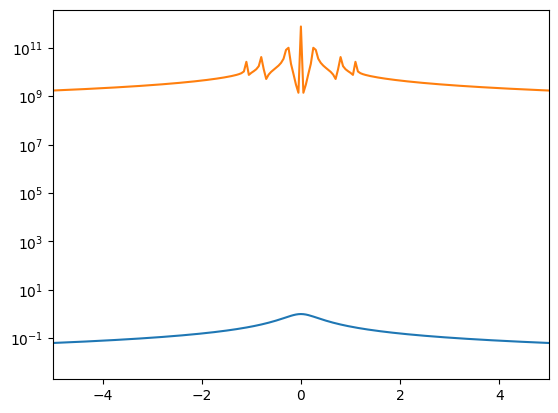

In [167]:
freqs = fftshift(fftfreq(len(times), d = times[1] - times[0]))
response_ft = fftshift(fft(ifftshift(resp)))
measured_ft = fftshift(fft(ifftshift(measured)))
plt.plot(freqs, [abs(_) for _ in response_ft])
plt.plot(freqs, [abs(_) for _ in measured_ft])
plt.xlim([-5, 5])
plt.yscale("log")
plt.show()

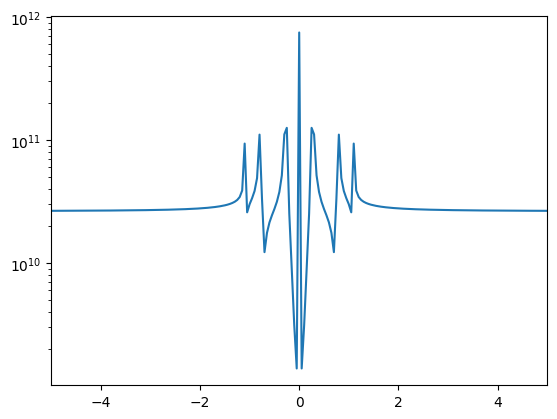

In [149]:
deconvolved_ft = [a / b for a, b in zip(measured_ft, response_ft)]
plt.plot(freqs, [abs(_) for _ in deconvolved_ft])
plt.yscale("log")
plt.xlim([-5, 5])
plt.show()

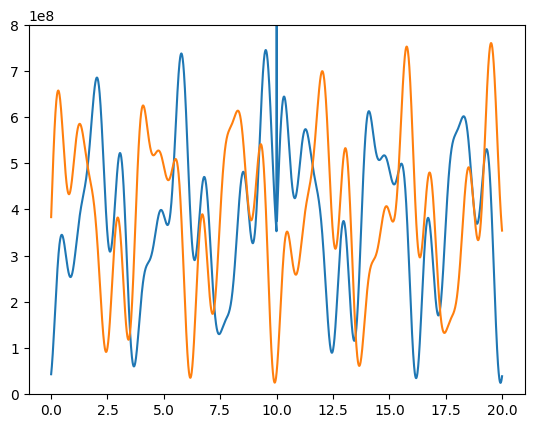

In [163]:
reconstructed_signal = fftshift(ifft(ifftshift(deconvolved_ft)))
plt.plot(times, [abs(_) for _ in reconstructed_signal])
plt.plot(times, intrinsic)
plt.ylim([0, 8e8])
plt.show()